In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_project_orders_full.csv")  
df.head()

,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,region,...,sub_category,product_name,sales,quantity,discount,profit,order_year,order_month,delivery_days,is_discounted
0,CA-2015-104346,2015-12-11,2015-12-16,Standard Class,IM-15070,Irene Maddox,Consumer,Florence,Alabama,South,...,Furnishings,"Master Caster Door Stop, Large Neon Orange",52.416,9,0.2,15.0696,2015,12,5,True
1,CA-2014-120768,2014-12-19,2014-12-21,Second Class,IM-15070,Irene Maddox,Consumer,Florence,Alabama,South,...,Chairs,High-Back Leather Manager's Chair,1819.860,14,0.0,163.7874,2014,12,2,False
2,CA-2015-104346,2015-12-11,2015-12-16,Standard Class,IM-15070,Irene Maddox,Consumer,Florence,Alabama,South,...,Furnishings,DAX Wood Document Frame,54.920,5,0.2,10.9840,2015,12,5,True
3,CA-2015-104346,2015-12-11,2015-12-16,Standard Class,IM-15070,Irene Maddox,Consumer,Florence,Alabama,South,...,Tables,Bevis Rectangular Conference Tables,364.950,5,0.5,-248.1660,2015,12,5,True
4,CA-2015-104346,2015-12-11,2015-12-16,Standard Class,IM-15070,Irene Maddox,Consumer,Florence,Alabama,South,...,Bookcases,"Bush Westfield Collection Bookcases, Dark Cher...",69.576,4,0.7,-143.7904,2015,12,5,True


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       2120 non-null   str    
 1   order_date     2120 non-null   str    
 2   ship_date      2120 non-null   str    
 3   ship_mode      2120 non-null   str    
 4   customer_id    2120 non-null   str    
 5   customer_name  2120 non-null   str    
 6   segment        2120 non-null   str    
 7   city           2120 non-null   str    
 8   state          2120 non-null   str    
 9   region         2120 non-null   str    
 10  product_id     2120 non-null   str    
 11  category       2120 non-null   str    
 12  sub_category   2120 non-null   str    
 13  product_name   2120 non-null   str    
 14  sales          2120 non-null   float64
 15  quantity       2120 non-null   int64  
 16  discount       2120 non-null   float64
 17  profit         2120 non-null   float64
 18  order_year     2120

In [6]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       2120 non-null   str           
 1   order_date     2120 non-null   datetime64[us]
 2   ship_date      2120 non-null   datetime64[us]
 3   ship_mode      2120 non-null   str           
 4   customer_id    2120 non-null   str           
 5   customer_name  2120 non-null   str           
 6   segment        2120 non-null   str           
 7   city           2120 non-null   str           
 8   state          2120 non-null   str           
 9   region         2120 non-null   str           
 10  product_id     2120 non-null   str           
 11  category       2120 non-null   str           
 12  sub_category   2120 non-null   str           
 13  product_name   2120 non-null   str           
 14  sales          2120 non-null   float64       
 15  quantity       2120 non-null   i

**Анализ (EDA)**

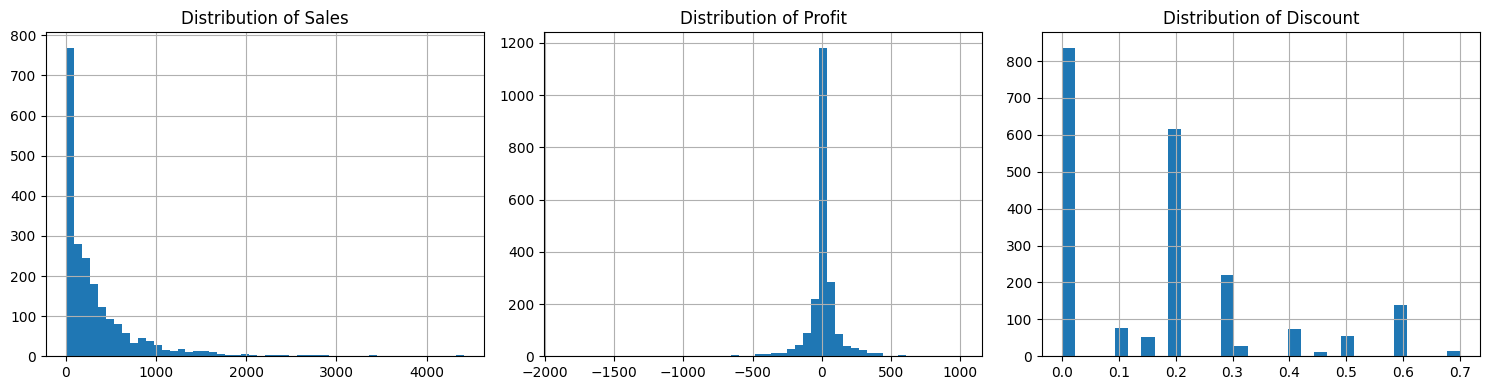

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['sales'].hist(bins=50, ax=axes[0]); axes[0].set_title('Distribution of Sales')
df['profit'].hist(bins=50, ax=axes[1]); axes[1].set_title('Distribution of Profit')
df['discount'].hist(bins=30, ax=axes[2]); axes[2].set_title('Distribution of Discount')
plt.tight_layout()
plt.show()

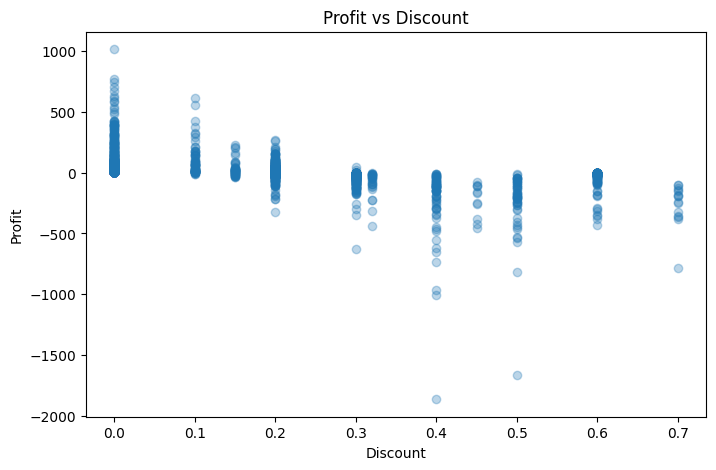

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(df['discount'], df['profit'], alpha=0.3)
plt.title('Profit vs Discount')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.show()

In [10]:
df[['sales', 'quantity', 'discount', 'profit']].corr()

,sales,quantity,discount,profit
sales,1.000000,0.437479,-0.028534,0.173502
quantity,0.437479,1.000000,-0.015439,0.061165
discount,-0.028534,-0.015439,1.000000,-0.483776
profit,0.173502,0.061165,-0.483776,1.000000


Продажи и прибыль сильно скошены, прибыль имеет выраженный отрицательный хвост, то-есть часть продаж убыточна. 

Скидки применяются фиксированными ступенями (0, 20%, 30%..) 

Скидка сильнее всех коррелирует с прибылью (−0.48) и негативно, тогда как объём продаж и количество почти не связаны с прибылью. 
Это указывает, что именно скидка это ключевой драйвер прибыльности

In [ ]:
from sklearn.linear_model import LinearRegression

X = df[['sales', 'discount', 'quantity']]
y = df['profit']

In [24]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.05,-359.2 , -1.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['sales','discount','quantity']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,59.79
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [25]:
print("Intercept (const):", model.intercept_)
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.2f}")

Intercept (const): 59.7860316540824
sales: 0.05
discount: -359.20
quantity: -1.21


Коэффициент при Discount равен −359, что значит что каждая дополнительная единица скидки (полный переход от 0 до 100%) снижает прибыль на 359$ при неизменных продажах и количестве. 

В практических терминах, каждые 10 процентных пунктов скидки уменьшают прибыль примерно на 36$ 

И это подтверждает, что скидка - главный негативный фактор прибыльности.

In [26]:
from sklearn.metrics import r2_score

y_pred = model.predict(X)
print("R²:", r2_score(y, y_pred))

R²: 0.2598864570642049


Модель объясняет 26% вариации прибыли (R² = 0.26) 

Скидка - доминирующий и статистически заметный негативный фактор, но невысокий R² показывает, что прибыльность определяется также и переменными вне модели (закупочной ценой, категорией, конкретным товаром) 

Это согласуется с находкой о структурно убыточных товарах в таблице Loss-Making Products Power BI, есть товары где закупочная цена выше или ценообразование сломано, не дающие прибыли ни разу. 

А также для точного прогноза модель следовало бы расширить категориальными признаками, т.к сейчас в модели только числовые признаки (sales, discount, quantity), и модель не знает, что товар это стол или стул, и из какого он региона

In [27]:
df['profit_pred'] = model.predict(X)
df.to_csv('forecast.csv', index=False)

In [28]:
df[['profit', 'profit_pred']].head(10)

,profit,profit_pred
0,15.0696,-20.531314
1,163.7874,125.826629
2,10.9840,-15.587864
3,-248.1660,-109.218182
4,-143.7904,-193.313337
5,0.6474,-13.080033
6,41.1684,63.841439
7,30.1872,59.784651
8,306.4894,99.502917
9,21.2940,27.274276
